In [1]:
import pickle
import warnings

warnings.filterwarnings('ignore')

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns

import myutils


In [2]:
workspace,experiment=myutils.workspace()

IS_FINE_TUNED = True

# run = "ms-Sep09-14-28"
run = "ms-Sep15-14-02"
# run = "ms-Sep03-14-24"
# run = "pred_ms-Sep17-11-12"
pred = 'fine-tuned' if IS_FINE_TUNED else 'wo-fine-tuning'
pred_dir = experiment / f'predictions/{pred}/{run}'
save_dir = experiment / f'save/dev_{run}' if IS_FINE_TUNED else pred_dir
pred_file = pred_dir/'pred_ms.h5ad'

data_dir = experiment/"scGPT/data/ms"
assert save_dir.exists()

In [3]:
with open(save_dir / 'results.pkl', 'rb') as f:
    results = pickle.load(f)
id2type = results['id_maps']
predictions = results['predictions']
labels = results['labels']
print(results.keys())
print()

if (pred_file.exists()):
    adata = sc.read(pred_file)
    print("PRED")
    print(adata)
else:
    pred_dir.mkdir(parents=True, exist_ok=True)
    adata = sc.read(data_dir / "filtered_ms_adata.h5ad")
    adata.var.set_index(adata.var["gene_name"], inplace=True)
    adata.obs["predictions"] = [id2type[p] for p in predictions]
    print("DEV")
    print(adata)

celltypes = adata.obs["celltype"].unique()
celltypes = list(celltypes)

dict_keys(['predictions', 'labels', 'results', 'id_maps'])

DEV
AnnData object with n_obs × n_vars = 13468 × 3000
    obs: 'Sample Characteristic[organism]', 'Sample Characteristic Ontology Term[organism]', 'Sample Characteristic[individual]', 'Sample Characteristic Ontology Term[individual]', 'Sample Characteristic[sex]', 'Sample Characteristic Ontology Term[sex]', 'Sample Characteristic[age]', 'Sample Characteristic Ontology Term[age]', 'Sample Characteristic[developmental stage]', 'Sample Characteristic Ontology Term[developmental stage]', 'Sample Characteristic[organism part]', 'Sample Characteristic Ontology Term[organism part]', 'Sample Characteristic[sampling site]', 'Sample Characteristic Ontology Term[sampling site]', 'Sample Characteristic[disease]', 'Sample Characteristic Ontology Term[disease]', 'Sample Characteristic[organism status]', 'Sample Characteristic Ontology Term[organism status]', 'Sample Characteristic[cause of death]', 'Sample Characteristic Ontology Term[cause

In [4]:
from collections import Counter

Counter(predictions)

Counter({6: 2067,
         8: 1730,
         7: 1536,
         3: 1199,
         4: 1151,
         12: 1107,
         15: 873,
         13: 860,
         0: 777,
         17: 608,
         5: 488,
         1: 373,
         2: 303,
         9: 255,
         10: 59,
         11: 46,
         16: 36})

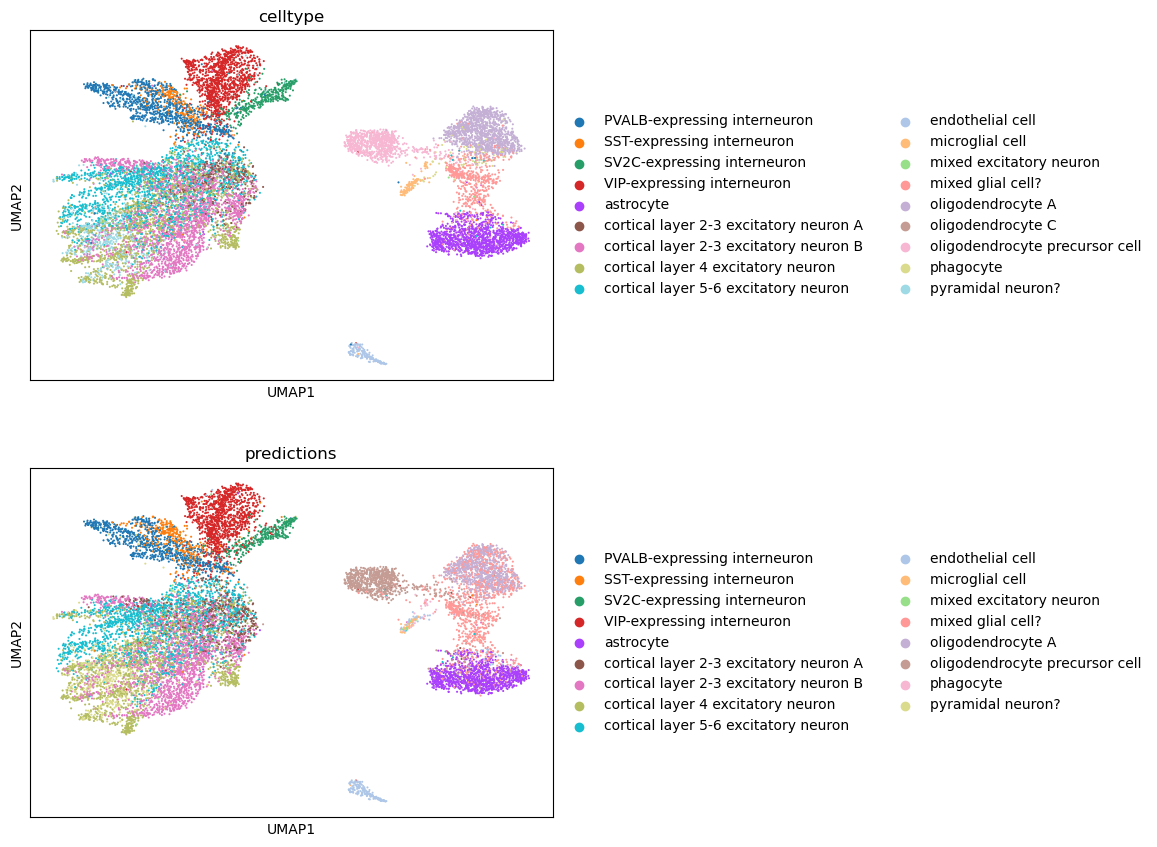

In [5]:
sc.pl.umap(
        adata,
        color=["celltype", "predictions"],
        ncols=1,
        show=False
    )
prediction_palette = dict(
    zip(
        adata.obs["predictions"].cat.categories,
        adata.uns["predictions_colors"],
    )
)
plt.savefig(pred_dir / "results.png", dpi=300, bbox_inches="tight")

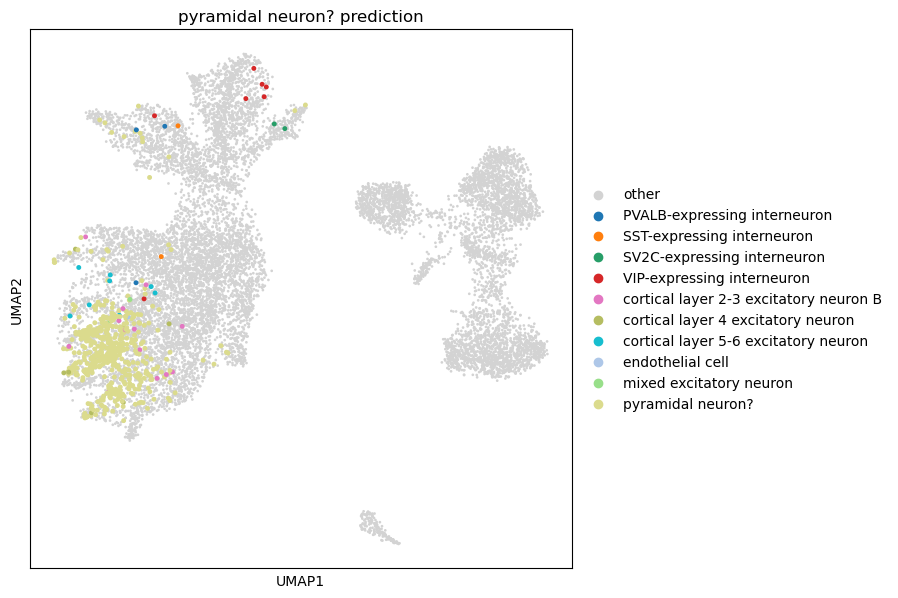

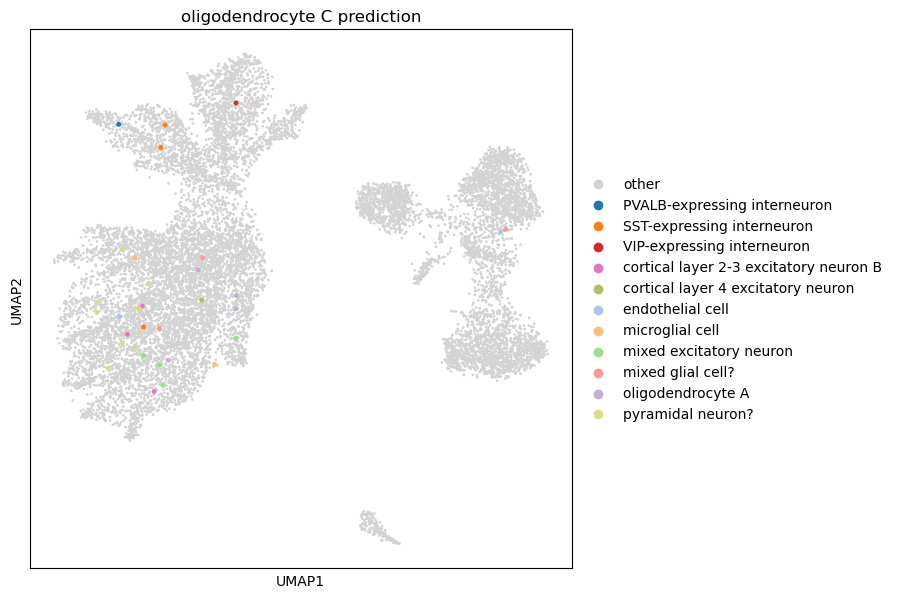

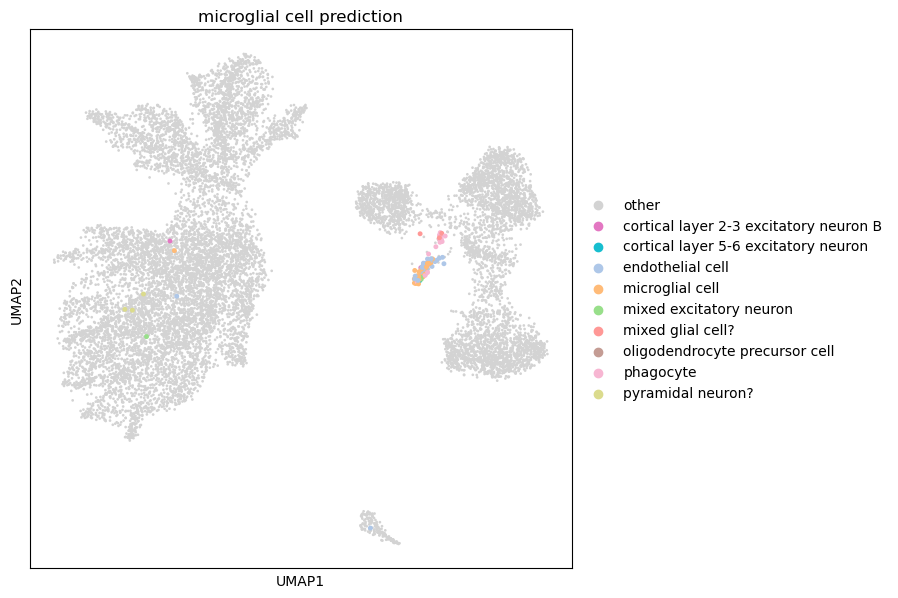

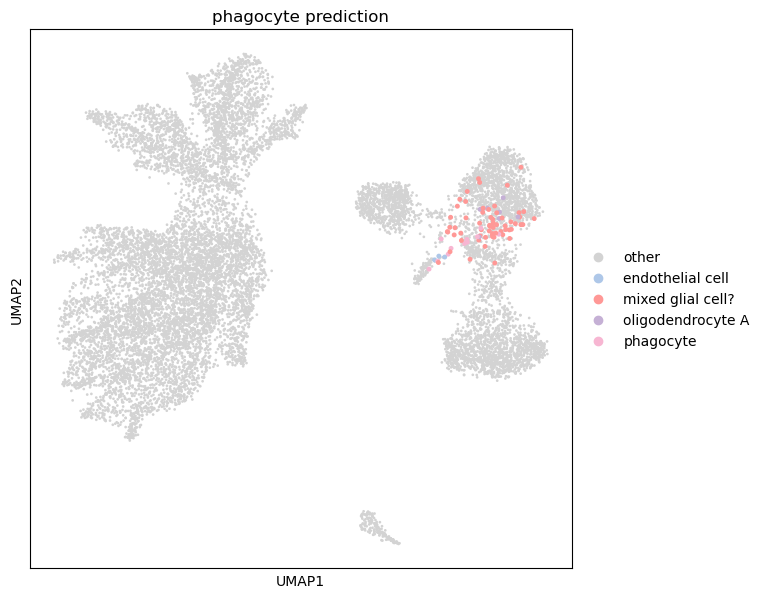

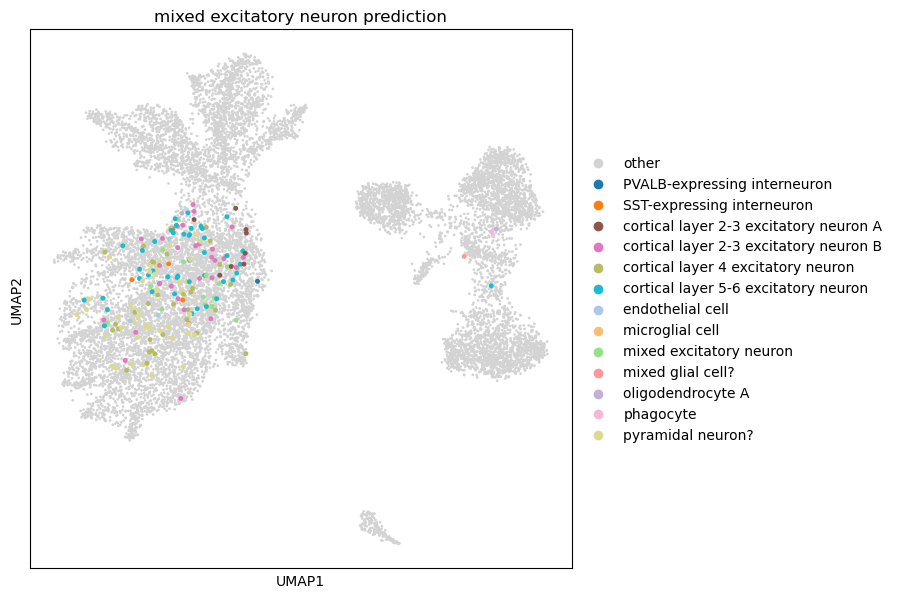

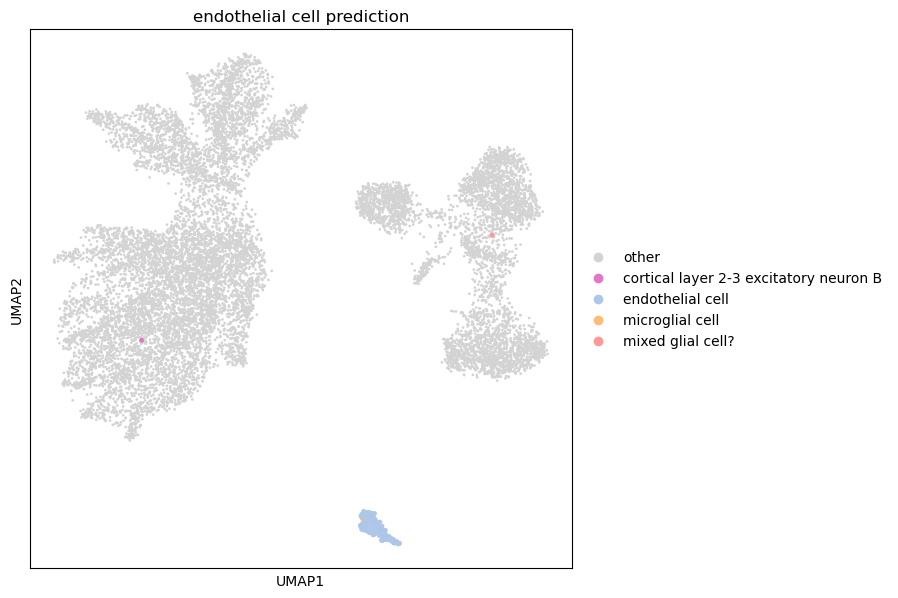

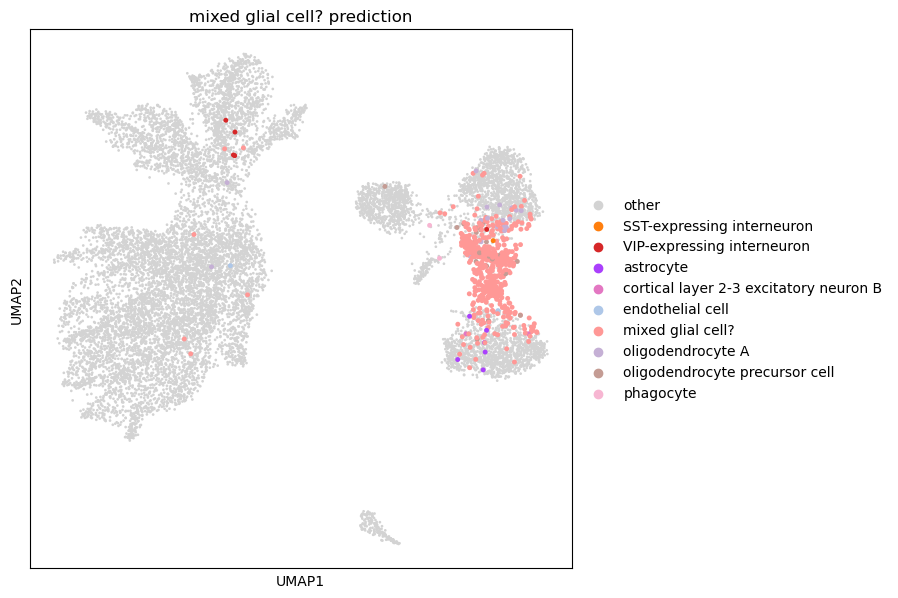

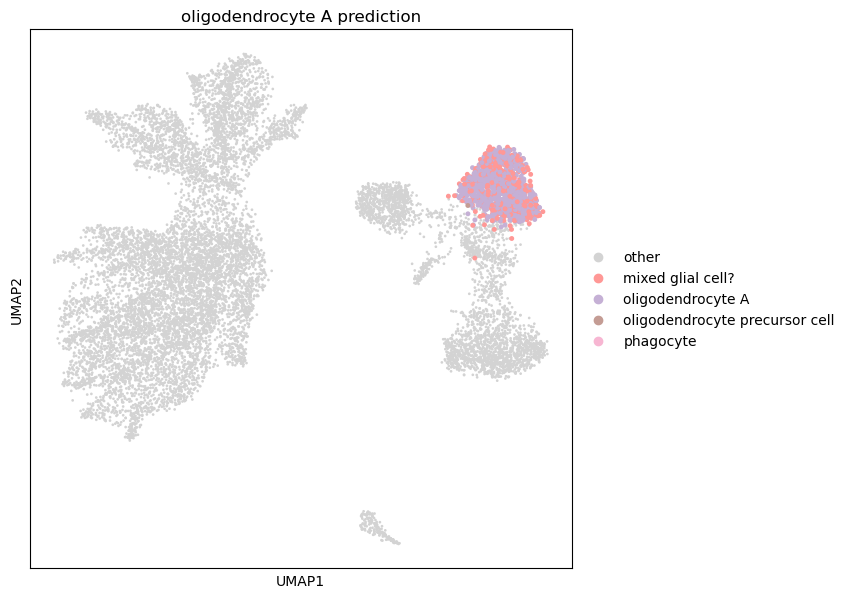

In [9]:
for celltype in ['pyramidal neuron?', 'oligodendrocyte C', 'microglial cell', 'phagocyte', 'mixed excitatory neuron','endothelial cell', 'mixed glial cell?', 'oligodendrocyte A']:
    myutils.inspect_prediction(adata, celltype, palette=prediction_palette, save_dir=pred_dir)

In [7]:
from sklearn.metrics import confusion_matrix

celltypes = [id2type[i] for i in range(len(celltypes))]
for i in {id2type[p] for p in predictions}:
    if i not in celltypes:
        celltypes.remove(i)
cm = confusion_matrix(labels, predictions)
cm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
cm = pd.DataFrame(cm, index=celltypes[:cm.shape[0]], columns=celltypes[:cm.shape[0]])

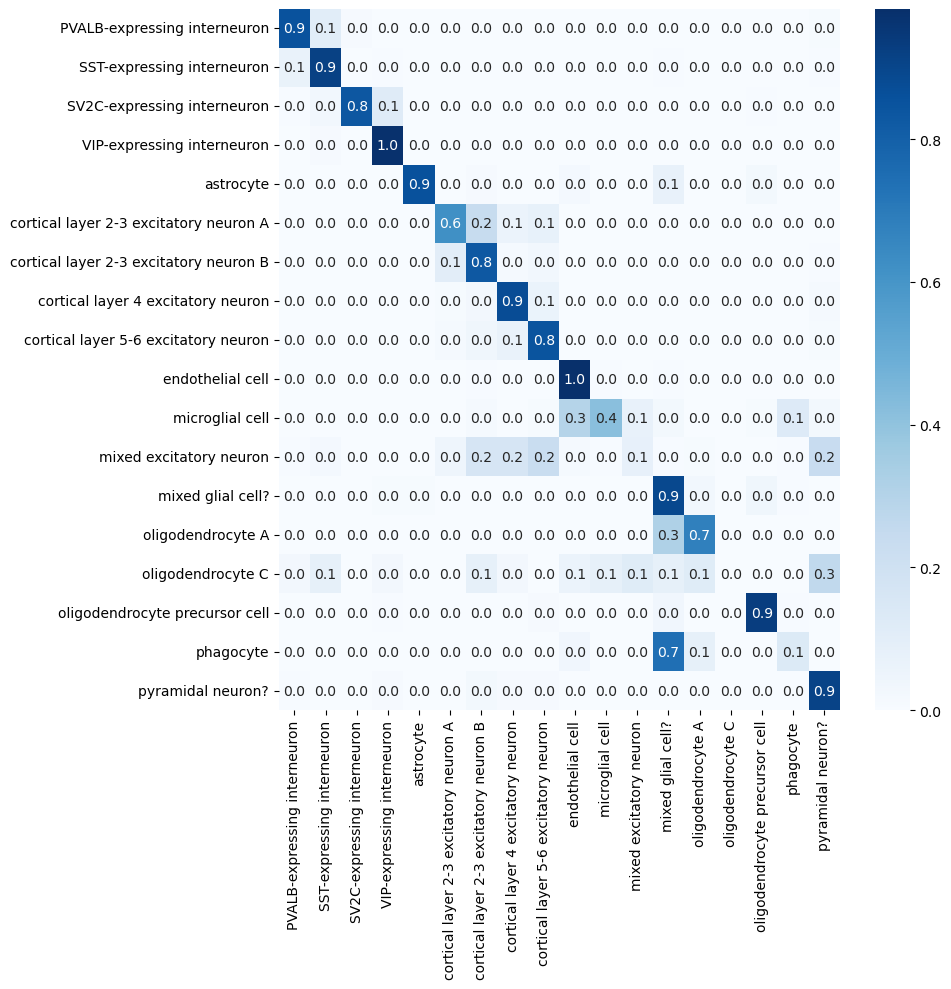

In [8]:
plt.figure(figsize=(10, 10))
sns.heatmap(cm, annot=True, fmt=".1f", cmap="Blues")
plt.tight_layout()
plt.savefig(pred_dir / "confusion_matrix.png", dpi=300, )